# Bivariate Analysis: Income and Selected Features

This notebook examines how age, weekly work hours, education, occupation,
and capital gain relate to income category in the UCI Adult training split.
Each record counts once.

Run from the repository root or `notebooks/` with the dependencies in
[requirements.txt](../requirements.txt). This notebook loads the training
data directly and can run independently of the univariate notebook.

In [11]:
from pathlib import Path

import pandas as pd

working_dir = Path.cwd()
schema_path = working_dir / "data" / "adult.names"
if not schema_path.is_file():
    schema_path = working_dir.parent / "data" / "adult.names"

if not schema_path.is_file():
    raise FileNotFoundError("Could not find data/adult.names. Run from the repository root or notebooks/.")

data_dir = schema_path.parent
feature_names = []
for line in schema_path.read_text(encoding="utf-8").splitlines():
    line = line.strip()
    if line and not line.startswith("|") and ":" in line:
        feature_names.append(line.split(":", maxsplit=1)[0].strip())

column_names = feature_names + ["income"]

read_options = {
    "names": column_names,
    "header": None,
    "skipinitialspace": True,
    "na_values": "?",
    "comment": "|",
}

train_data = pd.read_csv(data_dir / "adult.data", **read_options)

In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

income_order = ["<=50K", ">50K"]
assert train_data.shape == (32_561, 15), "Unexpected training file dimensions."
assert set(train_data["income"]) == set(income_order), "Unexpected income labels."

## Age and weekly work hours by income category

The line inside each box marks the median. The box spans the 25th to the
75th percentile. The whiskers extend to observations within 1.5 times the
interquartile range of the box, and points beyond the whiskers appear
individually. The labels show the number of records used for each box.

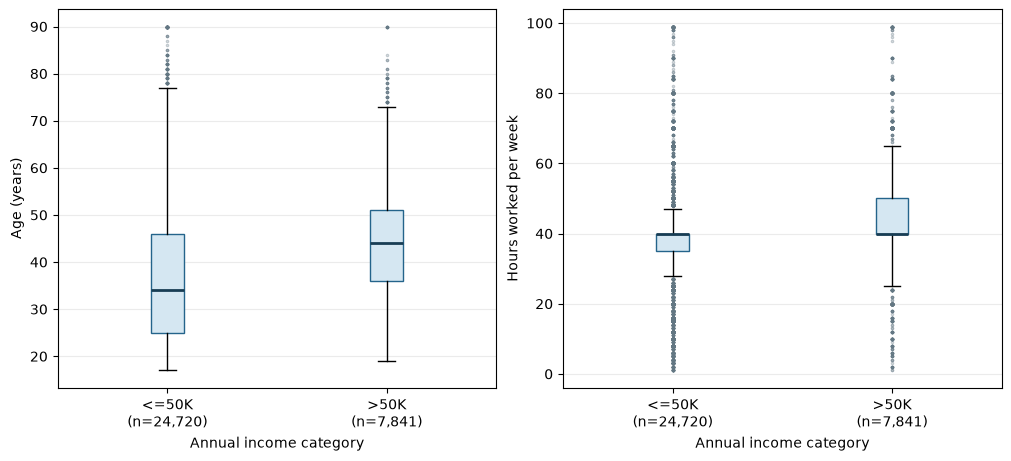

In [13]:
numeric_features = [
    ("age", "Age (years)"),
    ("hours-per-week", "Hours worked per week"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")

for ax, (feature, label) in zip(axes, numeric_features):
    samples = [
        train_data.loc[train_data["income"].eq(category), feature].dropna()
        for category in income_order
    ]
    tick_labels = [
        f"{category}\n(n={len(sample):,})"
        for category, sample in zip(income_order, samples)
    ]
    ax.boxplot(
        samples,
        tick_labels=tick_labels,
        patch_artist=True,
        boxprops={"facecolor": "#D5E7F2", "edgecolor": "#24648B"},
        medianprops={"color": "#183D54", "linewidth": 2},
        flierprops={"marker": ".", "markersize": 3, "markeredgecolor": "#637783", "alpha": 0.4},
    )
    ax.set(xlabel="Annual income category", ylabel=label)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.show()

### Age by income category
The median age is **34 years** in the <=50K group and **44 years** in the >50K group, so people in the >50K category tend to be older. The middle 50% of the two distributions still overlap, so people of similar ages appear in both income categories.
### Weekly work hours by income category
Both groups have a median of **40 hours per week**. The 75th percentile is 40 hours in the <=50K group and 50 hours in the >50K group, showing a difference in the upper half of the distributions that the medians alone do not capture.

## Share earning over $50,000 by education level

Each bar shows the percentage of records with income above $50,000 within
that education level. Levels follow the `education-num` order. The sample
size appears beside each level, and the dashed line shows the share across
the full training split.

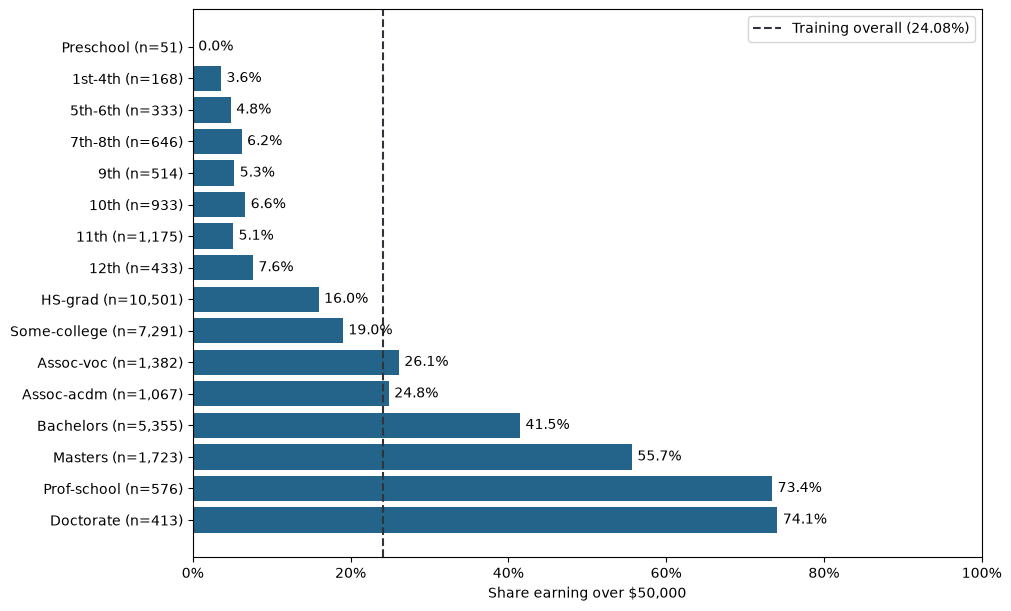

In [14]:
income_above_threshold = train_data["income"].eq(">50K")
overall_share = income_above_threshold.mean()

def summarize_income_by(groups):
    return income_above_threshold.groupby(groups, observed=True).agg(
        record_count="size", share_above_threshold="mean"
    )

def plot_income_shares(summary, height):
    labels = [
        f"{group} (n={count:,})"
        for group, count in summary["record_count"].items()
    ]
    shares = summary["share_above_threshold"]

    fig, ax = plt.subplots(figsize=(10, height), layout="constrained")
    bars = ax.barh(labels, shares, color="#24648B")
    ax.bar_label(bars, labels=[f"{share:.1%}" for share in shares], padding=4)
    ax.axvline(
        overall_share,
        color="#30343A",
        linestyle="--",
        label=f"Training overall ({overall_share:.2%})",
    )
    ax.invert_yaxis()
    ax.set(xlabel="Share earning over $50,000", xlim=(0, 1))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend(loc="upper right")
    plt.show()

education_summary = summarize_income_by(
    [train_data["education-num"], train_data["education"]]
).droplevel("education-num")
plot_income_shares(education_summary, height=6)

The share earning over $50,000 generally rises with education level. It is 16.0% for high school graduates, 41.5% for bachelor’s degree holders, and 55.7% for master’s degree holders, compared with 24.08% overall. Group sizes vary substantially, so percentages for smaller groups, such as Preschool with 51 records, should be interpreted with more caution.

## Share earning over $50,000 by occupation

Occupations are ordered by their share of records above $50,000.
`Missing` includes records with no occupation listed.

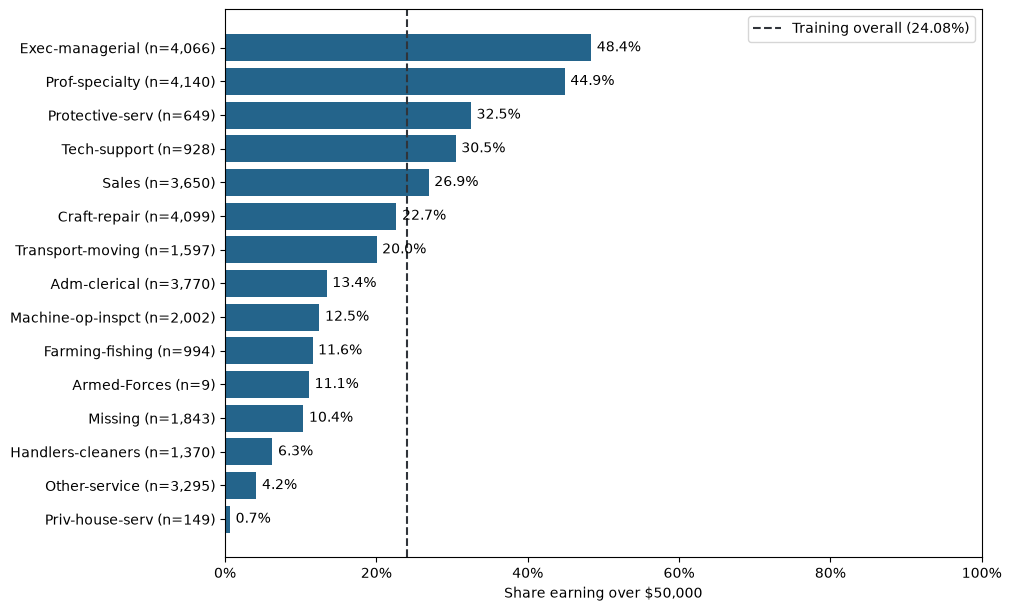

In [15]:
occupation_summary = summarize_income_by(train_data["occupation"].fillna("Missing"))
occupation_summary = occupation_summary.sort_values("share_above_threshold", ascending=False)
plot_income_shares(occupation_summary, height=6)

`Exec-managerial` and `Prof-specialty` have the highest shares above $50,000,
at **48.4%** and **44.9%**, respectively, with over 4,000 records in each group.
In `Armed-Forces`, the **11.1%** share represents one person out of nine.

## Share earning over $50,000 by weekly work hours

The groups are fewer than 40 hours, exactly 40 hours, and more than 40 hours.
Exactly 40 hours is shown separately because it is the most common value.

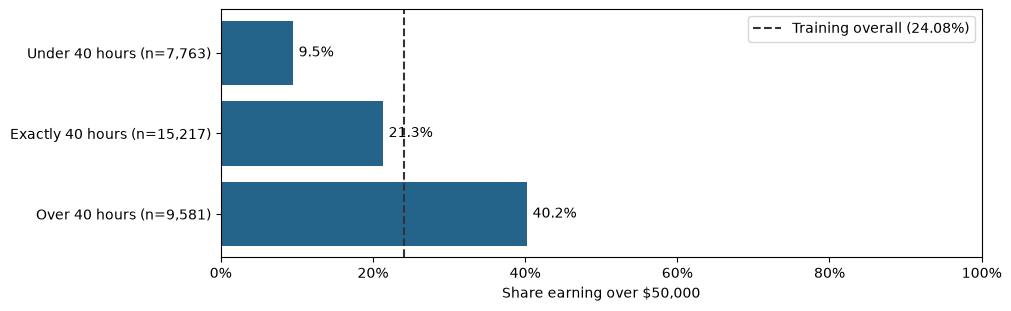

In [16]:
work_hours_group = pd.cut(
    train_data["hours-per-week"],
    bins=[-float("inf"), 39, 40, float("inf")],
    labels=["Under 40 hours", "Exactly 40 hours", "Over 40 hours"],
)
work_hours_summary = summarize_income_by(work_hours_group)
plot_income_shares(work_hours_summary, height=3)

The share above $50,000 rises from **9.5%** among people working fewer
than 40 hours to **21.3%** among those working exactly 40 hours and
**40.2%** among those working more than 40 hours. The 40-hour group is
the largest, with 15,217 records.

## Share earning over $50,000 by capital gain

The comparison groups records by whether the recorded capital gain is zero
or positive.

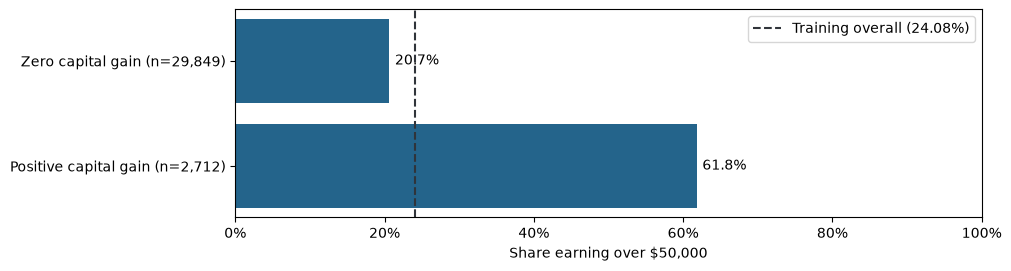

In [17]:
capital_gain_group = train_data["capital-gain"].gt(0).map(
    {False: "Zero capital gain", True: "Positive capital gain"}
)
capital_gain_summary = summarize_income_by(capital_gain_group).reindex(
    ["Zero capital gain", "Positive capital gain"]
)
plot_income_shares(capital_gain_summary, height=2.6)

The share above $50,000 is **61.8%** among records with positive capital
gain and **20.7%** among those with zero capital gain. The positive-gain
group contains 2,712 of the 32,561 training records.